
# Лабораторна робота №9 — Випадковий ліс (Random Forest)

### Проєкт DocVerify — OOB-оцінка, вплив кількості дерев, важливість ознак і стійкість до перенавчання

**Ланцюжок роботи:** підготовка даних → Random Forest → OOB-оцінка → вибір кількості дерев → аналіз важливості ознак → порівняння з деревом рішень → висновок.

**Як запускати.** Потрібні `numpy`, `pandas`, `matplotlib`, `scikit-learn` та `ipykernel`. Виконайте всі комірки (Run All): навчання моделей, таблиці, графіки та висновки обчислюються під час запуску. Результати зберігаються в папці `outputs`.


## 0. Підключення бібліотек

Код використовує ті самі `pandas`, `numpy`, `matplotlib` і `scikit-learn`, що й попередні лабораторні. Якщо середовище не має бібліотек, встановіть їх у терміналі: `python -m pip install numpy pandas matplotlib scikit-learn notebook ipykernel`. У Google Colab зазвичай нічого встановлювати не треба.

In [1]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "document_type"
AUTH_COLUMN = "authenticity"
FEATURES_CSV = Path("data/features_lab2.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

pd.set_option("display.max_colwidth", 65)
print("Бібліотеки імпортовано. Папка результатів:", OUTPUT_DIR.resolve())

Бібліотеки імпортовано. Папка результатів: D:\Paru\4\лаб9\DocVerify\outputs


## 1. Завантаження даних DocVerify

Базовий файл розташований у GitHub-репозиторії команди. Якщо запускаємо з папки проєкту, використовуємо **локальний файл**. Якщо це Google Colab без клонованого репозиторію, таблиця завантажується за **публічним прямим посиланням** GitHub. Ми не завантажуємо зображення: усі потрібні метадані вже у CSV.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/MariiaHudymenko/DocVerify/"
    "main/data/features_lab2.csv"
)

if FEATURES_CSV.exists():
    print("Джерело: локальний", FEATURES_CSV)
    df = pd.read_csv(FEATURES_CSV)
else:
    print("Локальний CSV не знайдено. Завантажую відкритий CSV із GitHub...")
    df = pd.read_csv(DATA_URL)
    print("Джерело: GitHub (гілка main)")

NUMERIC_COLS = [
    "width", "height", "file_size_bytes", "aspect_ratio",
    "std_brightness", "dark_pixel_ratio",
]
CATEGORICAL_COLS = ["source_dataset", "authenticity"]
REQUIRED_COLS = [TARGET, *NUMERIC_COLS, *CATEGORICAL_COLS]
missing = sorted(set(REQUIRED_COLS) - set(df.columns))
if missing:
    raise ValueError(f"У CSV не вистачає колонок: {missing}")

print("Рядків:", len(df))
print("Класів:", df[TARGET].nunique())
print("Колонок у вихідному CSV:", len(df.columns))
print("Порожніх authenticity:", df[AUTH_COLUMN].isna().sum())
display(df.head(3))

# Історичний набір містить 3682 об'єкти й 20 класів.
if (len(df), df[TARGET].nunique()) != (3682, 20):
    print("Увага: дані відрізняються від набору ЛР №2–8; числа можуть відрізнятись.")

Джерело: локальний data\features_lab2.csv
Рядків: 3682
Класів: 20
Колонок у вихідному CSV: 12
Порожніх authenticity: 3349


,filename,document_type,source_dataset,authenticity,width,height,file_size_bytes,aspect_ratio,mean_brightness,std_brightness,dark_pixel_ratio,color_saturation_mean
0,rahunok/rahunok_0000.png,рахунок,RVL-CDIP,NaN,802,1000,100163,0.802,250.871021,26.578634,0.015262,0.0
1,rahunok/rahunok_0001.png,рахунок,RVL-CDIP,NaN,777,1000,198897,0.777,234.195624,65.284716,0.080224,0.0
2,rahunok/rahunok_0002.png,рахунок,RVL-CDIP,NaN,754,1000,349049,0.754,231.765775,62.040539,0.083447,0.0


## 2. Підготовка train/test та 13 ознак

- `authenticity` → `not_applicable` для документів, де її не визначено.
- Ціль `document_type` кодуємо через `LabelEncoder` (20 класів).
- `train_test_split` використовує **`test_size=0.2`, `stratify=y`, `random_state=42`** — як ЛР №2–8.
- Для `width` і `file_size_bytes` застосовуємо IQR capping. **Межі рахуємо на train**, а test обрізаємо за тими самими межами.
- `StandardScaler` застосовуємо до **шести числових** ознак; категоріальні — `OneHotEncoder`.
- `mean_brightness` і `color_saturation_mean` **не включаємо**, щоб не змінити історичний простір із 13 ознак.

> У дерев масштабування не обов'язкове. Але тут воно залишене, оскільки це спільний простір із попередніх лабораторних.

In [3]:
df = df.copy()
df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna("not_applicable")

for column in NUMERIC_COLS:
    df[column] = pd.to_numeric(df[column], errors="raise")

if df[NUMERIC_COLS + [TARGET, "source_dataset", AUTH_COLUMN]].isna().any().any():
    raise ValueError("У потрібних ознаках є неочікувані пропуски")

le_target = LabelEncoder()
y = le_target.fit_transform(df[TARGET])

# Поділ за тими самими індексами, що в ЛР №5.
train_idx, test_idx = train_test_split(
    df.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

df_train = df.loc[train_idx].copy()
df_test = df.loc[test_idx].copy()
y_train, y_test = y[train_idx], y[test_idx]

# Навчаємо IQR-межі виключно на train — без витоку test у навчання.
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr)

CAP_COLS = ["width", "file_size_bytes"]
cap_bounds = {column: iqr_bounds(df_train[column]) for column in CAP_COLS}
for column, (lower, upper) in cap_bounds.items():
    df_train[column] = df_train[column].clip(lower=lower, upper=upper)
    df_test[column] = df_test[column].clip(lower=lower, upper=upper)

# Врахування старіших версій scikit-learn (sparse_output з'явився у 1.2).
try:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
except TypeError:
    ohe = OneHotEncoder(sparse=False, handle_unknown="ignore")

X_train_cat = ohe.fit_transform(df_train[CATEGORICAL_COLS])
X_test_cat = ohe.transform(df_test[CATEGORICAL_COLS])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(df_train[NUMERIC_COLS])
X_test_num = scaler.transform(df_test[NUMERIC_COLS])

X_train = np.hstack([X_train_num, X_train_cat])
X_test = np.hstack([X_test_num, X_test_cat])
feature_names = NUMERIC_COLS + list(ohe.get_feature_names_out(CATEGORICAL_COLS))

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Кількість ознак:", len(feature_names))
print("Назви ознак:", feature_names)
print("IQR-межі, обчислені лише на train:", cap_bounds)
assert X_train.shape[1] == X_test.shape[1] == len(feature_names)
assert set(train_idx).isdisjoint(set(test_idx)), "Train/test перетинаються!"
assert not np.isnan(X_train).any() and not np.isnan(X_test).any()
if len(df) == 3682 and df[TARGET].nunique() == 20:
    assert X_train.shape == (2945, 13)
    assert X_test.shape == (737, 13)
    print("Перевірка пройдена: 2945 / 737, 13 ознак (як у ЛР №5).")

Train: (2945, 13) Test: (737, 13)
Кількість ознак: 13
Назви ознак: ['width', 'height', 'file_size_bytes', 'aspect_ratio', 'std_brightness', 'dark_pixel_ratio', 'source_dataset_Dummy KTP Indonesia (Kaggle)', 'source_dataset_MIDV-500 (Wikimedia Commons, FTP smartengines.com)', 'source_dataset_RVL-CDIP', 'source_dataset_SROIE/CORD', 'source_dataset_Synthetic Passports Dataset (Kaggle)', 'authenticity_genuine', 'authenticity_not_applicable']
IQR-межі, обчислені лише на train: {'width': (719.5, 811.5), 'file_size_bytes': (-253772.5, 782807.5)}
Перевірка пройдена: 2945 / 737, 13 ознак (як у ЛР №5).


## 3. Частина 1 — базовий випадковий ліс із 200 деревами та OOB

**Random Forest** — це ансамбль дерев, навчених на різних випадкових вибірках (bootstrap). На кожному розбитті дерева випадково розглядається частина ознак (`max_features='sqrt'`).

**OOB (Out-of-Bag)** — це оцінка якості на навчальних об'єктах, що **не потрапили** до bootstrap-вибірки певних дерев. Вона розраховується без використання `X_test`.

Далі обчислюємо `train accuracy`, `test accuracy`, `OOB accuracy`, `test F1-macro`, різницю train−test та час навчання.

In [4]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    train_accuracy = accuracy_score(y_train, pred_train)
    test_accuracy = accuracy_score(y_test, pred_test)
    return {
        "model": model,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "gap": train_accuracy - test_accuracy,
        "f1_macro": f1_score(y_test, pred_test, average="macro", zero_division=0),
        "fit_seconds": fit_seconds,
        "pred_test": pred_test,
    }

rf200 = RandomForestClassifier(
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_result = evaluate_model(rf200, X_train, y_train, X_test, y_test)

print("ЧАСТИНА 1. ВИПАДКОВИЙ ЛІС — 200 ДЕРЕВ")
print(f"Train accuracy: {rf_result['train_accuracy']:.4f} ({100*rf_result['train_accuracy']:.2f}%)")
print(f"OOB accuracy:   {rf200.oob_score_:.4f} ({100*rf200.oob_score_:.2f}%)")
print(f"OOB error:      {1 - rf200.oob_score_:.4f}")
print(f"Test accuracy:  {rf_result['test_accuracy']:.4f} ({100*rf_result['test_accuracy']:.2f}%)")
print(f"F1-macro:       {rf_result['f1_macro']:.4f}")
print(f"Train-Test gap: {rf_result['gap']:.4f}")
print(f"|OOB-Test|:     {abs(rf200.oob_score_ - rf_result['test_accuracy']):.4f}")
print(f"Час навчання:   {rf_result['fit_seconds']:.3f} с")
print("\nClassification Report:\n")
print(classification_report(y_test, rf_result["pred_test"],
                            target_names=le_target.classes_, zero_division=0))

ЧАСТИНА 1. ВИПАДКОВИЙ ЛІС — 200 ДЕРЕВ
Train accuracy: 1.0000 (100.00%)
OOB accuracy:   0.3671 (36.71%)
OOB error:      0.6329
Test accuracy:  0.3786 (37.86%)
F1-macro:       0.4000
Train-Test gap: 0.6214
|OOB-Test|:     0.0115
Час навчання:   0.695 с

Classification Report:

                    precision    recall  f1-score   support

         ID-картка       1.00      1.00      1.00        20
             email       0.52      0.58      0.55        38
            анкета       0.07      0.05      0.06        38
            бюджет       0.17      0.16      0.16        38
         квитанція       1.00      1.00      1.00        40
              лист       0.09      0.11      0.10        44
наукова публікація       0.29      0.32      0.30        38
     науковий звіт       0.10      0.08      0.09        38
    новинна стаття       0.13      0.11      0.12        38
           паспорт       1.00      1.00      1.00        27
 посвідчення водія       1.00      1.00      1.00        36
   

## 4. Частина 2 — як `n_estimators` впливає на точність і час

Усі експерименти проводимо на **тих самих** train і test, за фіксованого `random_state=42`.

Значення: **10, 50, 100, 200, 500 дерев**. Вимірюємо час `fit()`, `train accuracy`, `test accuracy`, `OOB accuracy`. Для малої кількості дерев OOB-оцінка може бути менш надійною, адже не кожен об'єкт має достатньо OOB-голосів. Тому також показуємо **покриття OOB**.

> Важливо: у лабораторній просили **дослідити** test accuracy, але вибирати гіперпараметри для остаточної продукційної моделі за тестом некоректно. Тут тест використовується для навчального порівняльного графіка. Основний базовий варіант 200 дерев заданий презентацією.

In [5]:
N_ESTIMATORS_LIST = [10, 50, 100, 200, 500]
forest_rows = []
forest_models = {}

for n in N_ESTIMATORS_LIST:
    # Повторно не навчаємо rf200; отримуємо ту саму модель і її час.
    if n == 200:
        rf = rf200
        res = rf_result
    else:
        rf = RandomForestClassifier(
            n_estimators=n,
            bootstrap=True,
            oob_score=True,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        # За 10 дерев sklearn іноді попереджає про неповне OOB-покриття.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
            res = evaluate_model(rf, X_train, y_train, X_test, y_test)

    forest_models[n] = rf
    oob_probs = rf.oob_decision_function_
    oob_coverage = np.mean(oob_probs.sum(axis=1) > 0)
    forest_rows.append({
        "n_estimators": n,
        "train_accuracy": res["train_accuracy"],
        "oob_accuracy": rf.oob_score_,
        "test_accuracy": res["test_accuracy"],
        "f1_macro": res["f1_macro"],
        "fit_seconds": res["fit_seconds"],
        "oob_coverage": oob_coverage,
    })

forest_df = pd.DataFrame(forest_rows).sort_values("n_estimators")
print("ЧАСТИНА 2. ЯКІСТЬ ЗАЛЕЖНО ВІД КІЛЬКОСТІ ДЕРЕВ")
display(forest_df.round(4))
forest_df.to_csv(OUTPUT_DIR / "lab9_estimators.csv", index=False, encoding="utf-8-sig")
print("Збережено:", OUTPUT_DIR / "lab9_estimators.csv")

ЧАСТИНА 2. ЯКІСТЬ ЗАЛЕЖНО ВІД КІЛЬКОСТІ ДЕРЕВ


,n_estimators,train_accuracy,oob_accuracy,test_accuracy,f1_macro,fit_seconds,oob_coverage
0,10,0.9810,0.3301,0.3609,0.3847,0.0574,0.9898
1,50,0.9997,0.3542,0.3799,0.4019,0.1870,1.0000
2,100,1.0000,0.3647,0.3840,0.4058,0.3860,1.0000
3,200,1.0000,0.3671,0.3786,0.4000,0.6953,1.0000
4,500,1.0000,0.3708,0.3813,0.4031,1.8685,1.0000


Збережено: outputs\lab9_estimators.csv


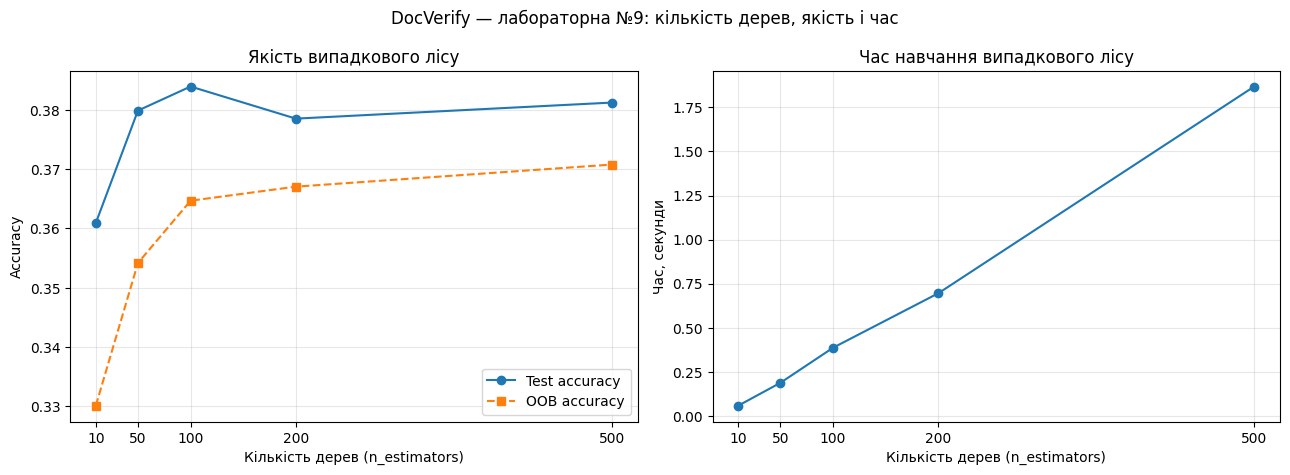

Збережено: outputs/fig_lab9_accuracy_time.png
Орієнтовне плато (всі наступні точки в межах ±1 в.п. від 500 дерев): від 50 дерев
Це лише критерій для п'яти перевірених значень, а не гарантія ідеального плато.


In [6]:
# Діаграма 1: точність та OOB залежно від числа дерев.
# Діаграма 2: скільки часу потрібно для навчання.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(forest_df["n_estimators"], forest_df["test_accuracy"], "o-", label="Test accuracy")
axes[0].plot(forest_df["n_estimators"], forest_df["oob_accuracy"], "s--", label="OOB accuracy")
axes[0].set(xlabel="Кількість дерев (n_estimators)", ylabel="Accuracy", title="Якість випадкового лісу")
axes[0].set_xticks(N_ESTIMATORS_LIST)
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(forest_df["n_estimators"], forest_df["fit_seconds"], "o-")
axes[1].set(xlabel="Кількість дерев (n_estimators)", ylabel="Час, секунди", title="Час навчання випадкового лісу")
axes[1].set_xticks(N_ESTIMATORS_LIST)
axes[1].grid(alpha=0.3)
fig.suptitle("DocVerify — лабораторна №9: кількість дерев, якість і час")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_lab9_accuracy_time.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Збережено: outputs/fig_lab9_accuracy_time.png")

# Умовне «плато»: після якого n різниця з accuracy при 500 деревах <= 1 п.п.
ref_accuracy = float(forest_df.iloc[-1]["test_accuracy"])
# Шукаємо перше n, після якого УСІ подальші точки не відхиляються
# від результату для 500 дерев більше ніж на 1 відсотковий пункт.
first_stable = 500
for index, row in forest_df.reset_index(drop=True).iterrows():
    subsequent = forest_df.iloc[index:]["test_accuracy"]
    if (abs(subsequent - ref_accuracy) <= 0.01).all():
        first_stable = int(row["n_estimators"])
        break
print(f"Орієнтовне плато (всі наступні точки в межах ±1 в.п. від 500 дерев): від {first_stable} дерев")
print("Це лише критерій для п'яти перевірених значень, а не гарантія ідеального плато.")

## 5. Частина 3 — дерево рішень із ЛР №5 та порівняння train/test

В ЛР №5 було **два** дерева:
1. Базове: `DecisionTreeClassifier(random_state=42)` (без обмеження глибини).
2. Після `GridSearchCV`: `max_depth=10`, `min_samples_leaf=10`, `random_state=42`.

**Історичні результати ЛР №5:** базове дерево: train **1.0000**, test **0.3175**, розрив **0.6825**; оптимізоване дерево: train **0.3902**, test **0.3677**, розрив **0.0225**. Це числа **з попереднього звіту**, а не результат нової комірки.

Тепер **переобчислюємо** ці дерева на нашому train-only препроцесингу для чесного порівняння із Random Forest. Це не підміна ЛР №5 — це контроль умов експерименту.

,model,train_accuracy,test_accuracy,gap_train_test,f1_macro
0,Дерево без обмежень (ЛР №5),1.0000,0.3175,0.6825,0.3457
1,Дерево оптимізоване (ЛР №5),0.3902,0.3677,0.0224,0.3532
2,Random Forest (200 дерев),1.0000,0.3786,0.6214,0.4000


Збережено: outputs/lab9_comparison.csv

Історичні дані з оригінальної ЛР №5 (без перерахунку):


,model,train_accuracy,test_accuracy,gap
0,Дерево без обмежень,1.0000,0.3175,0.6825
1,Дерево після GridSearchCV,0.3902,0.3677,0.0225


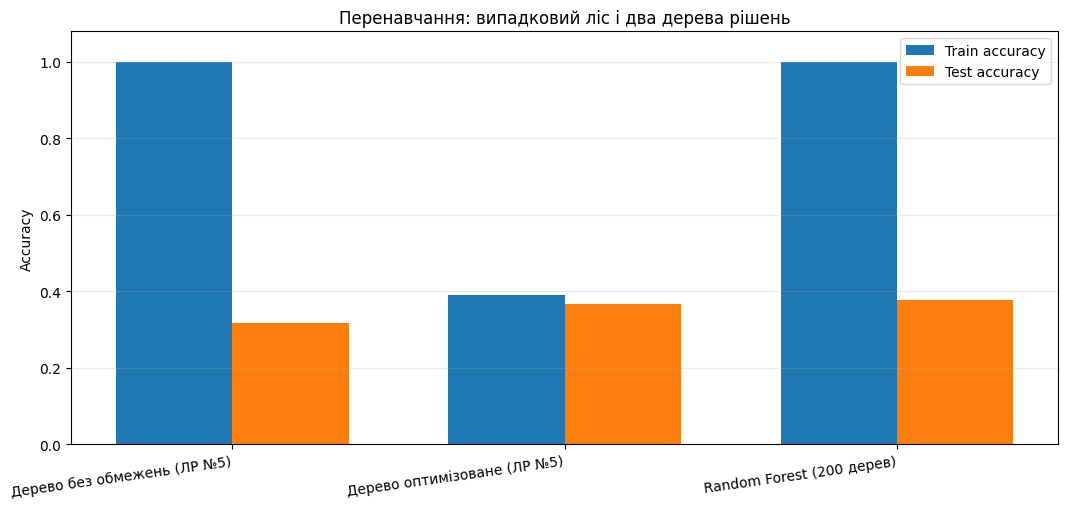

Збережено: outputs/fig_lab9_train_test_comparison.png


In [7]:
tree_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_opt = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=10,
    random_state=RANDOM_STATE,
)

base_result = evaluate_model(tree_base, X_train, y_train, X_test, y_test)
opt_result = evaluate_model(tree_opt, X_train, y_train, X_test, y_test)

comparison_df = pd.DataFrame([
    {
        "model": "Дерево без обмежень (ЛР №5)",
        "train_accuracy": base_result["train_accuracy"],
        "test_accuracy": base_result["test_accuracy"],
        "gap_train_test": base_result["gap"],
        "f1_macro": base_result["f1_macro"],
    },
    {
        "model": "Дерево оптимізоване (ЛР №5)",
        "train_accuracy": opt_result["train_accuracy"],
        "test_accuracy": opt_result["test_accuracy"],
        "gap_train_test": opt_result["gap"],
        "f1_macro": opt_result["f1_macro"],
    },
    {
        "model": "Random Forest (200 дерев)",
        "train_accuracy": rf_result["train_accuracy"],
        "test_accuracy": rf_result["test_accuracy"],
        "gap_train_test": rf_result["gap"],
        "f1_macro": rf_result["f1_macro"],
    },
])

display(comparison_df.round(4))
comparison_df.to_csv(OUTPUT_DIR / "lab9_comparison.csv", index=False, encoding="utf-8-sig")
print("Збережено: outputs/lab9_comparison.csv")
print("\nІсторичні дані з оригінальної ЛР №5 (без перерахунку):")
display(pd.DataFrame([
    {"model": "Дерево без обмежень", "train_accuracy": 1.0000, "test_accuracy": 0.3175, "gap": 0.6825},
    {"model": "Дерево після GridSearchCV", "train_accuracy": 0.3902, "test_accuracy": 0.3677, "gap": 0.0225},
]))

fig, ax = plt.subplots(figsize=(11, 5.2))
pos = np.arange(len(comparison_df))
width = 0.35
ax.bar(pos - width/2, comparison_df["train_accuracy"], width, label="Train accuracy")
ax.bar(pos + width/2, comparison_df["test_accuracy"], width, label="Test accuracy")
ax.set_xticks(pos, comparison_df["model"], rotation=8, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Accuracy")
ax.set_title("Перенавчання: випадковий ліс і два дерева рішень")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_lab9_train_test_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Збережено: outputs/fig_lab9_train_test_comparison.png")

## 6. Важливість ознак: дерево з ЛР №5 проти випадкового лісу

В обох моделях беремо `feature_importances_` (зменшення нечистоти Джині/Gini importance). На відміну від одного дерева, у лісі важливість узагальнюється за багатьма деревами. Важливість **не доводить причинність**: особливо обережно трактуємо `source_dataset` та `authenticity`, адже джерело набору пов'язане з типами документів.

**Історичний top-3 дерева з ЛР №5:** `source_dataset_SROIE/CORD` ≈ 0.2031, `source_dataset_MIDV-500 ...` ≈ 0.1838, `file_size_bytes` ≈ 0.1664. У цій роботі заново рахуємо обидва набори важливостей на одних даних.

ВАЖЛИВІСТЬ ОЗНАК — СОРТУВАННЯ ЗА ВИПАДКОВИМ ЛІСОМ


,feature,decision_tree_importance,random_forest_importance
2,file_size_bytes,0.1664,0.2460
5,dark_pixel_ratio,0.0733,0.2328
4,std_brightness,0.0557,0.2303
3,aspect_ratio,0.0398,0.0861
0,width,0.0357,0.0688
9,source_dataset_SROIE/CORD,0.2031,0.0255
7,"source_dataset_MIDV-500 (Wikimedia Commons, FTP smartengines....",0.1838,0.0221
8,source_dataset_RVL-CDIP,0.1049,0.0192
11,authenticity_genuine,0.1374,0.0162
12,authenticity_not_applicable,0.0000,0.0160


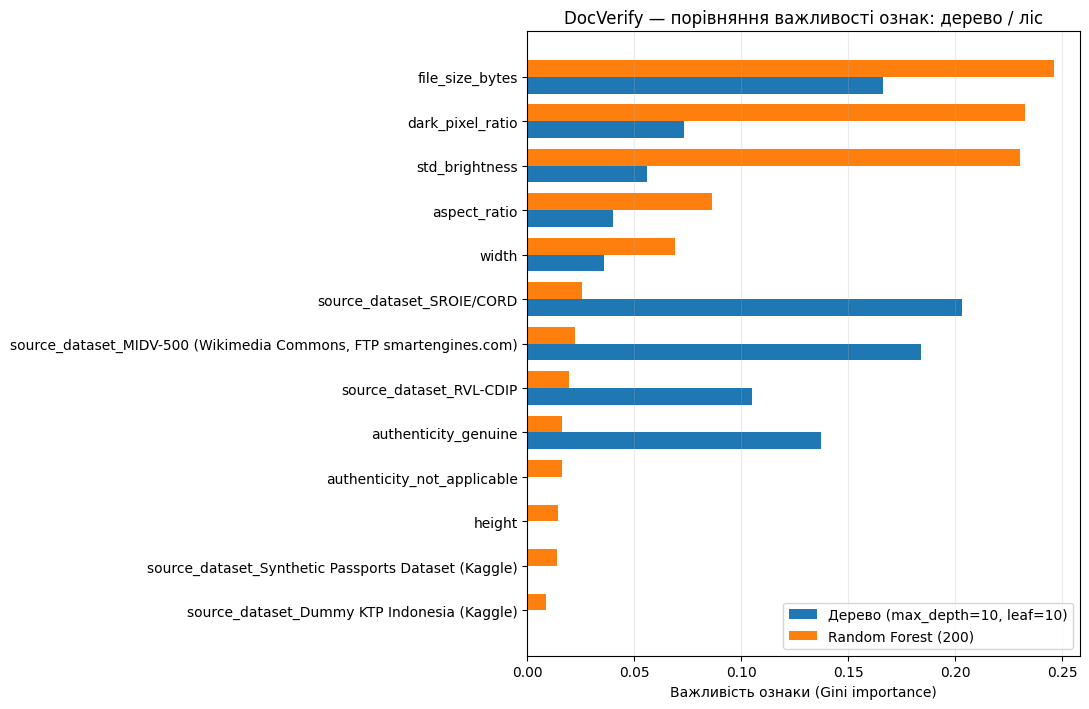

Топ-3 випадкового лісу:
1. file_size_bytes: 0.2460
2. dark_pixel_ratio: 0.2328
3. std_brightness: 0.2303
Топ-3 оптимізованого дерева:
1. source_dataset_SROIE/CORD: 0.2031
2. source_dataset_MIDV-500 (Wikimedia Commons, FTP smartengines.com): 0.1838
3. file_size_bytes: 0.1664
Збережено: outputs/lab9_feature_importances.csv і outputs/fig_lab9_feature_importances.png


In [8]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "decision_tree_importance": tree_opt.feature_importances_,
    "random_forest_importance": rf200.feature_importances_,
}).sort_values("random_forest_importance", ascending=False)

print("ВАЖЛИВІСТЬ ОЗНАК — СОРТУВАННЯ ЗА ВИПАДКОВИМ ЛІСОМ")
display(importance_df.round(4))
importance_df.to_csv(OUTPUT_DIR / "lab9_feature_importances.csv", index=False, encoding="utf-8-sig")

plot_data = importance_df.iloc[::-1]
y_pos = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(11, 7.2))
bar_h = 0.38
ax.barh(y_pos - bar_h/2, plot_data["decision_tree_importance"], height=bar_h, label="Дерево (max_depth=10, leaf=10)")
ax.barh(y_pos + bar_h/2, plot_data["random_forest_importance"], height=bar_h, label="Random Forest (200)")
ax.set_yticks(y_pos, plot_data["feature"])
ax.set_xlabel("Важливість ознаки (Gini importance)")
ax.set_title("DocVerify — порівняння важливості ознак: дерево / ліс")
ax.legend()
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_lab9_feature_importances.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Топ-3 випадкового лісу:")
for idx, row in enumerate(importance_df.head(3).itertuples(index=False), start=1):
    print(f"{idx}. {row.feature}: {row.random_forest_importance:.4f}")
print("Топ-3 оптимізованого дерева:")
top_tree = importance_df.sort_values("decision_tree_importance", ascending=False).head(3)
for idx, row in enumerate(top_tree.itertuples(index=False), start=1):
    print(f"{idx}. {row.feature}: {row.decision_tree_importance:.4f}")
print("Збережено: outputs/lab9_feature_importances.csv і outputs/fig_lab9_feature_importances.png")

## 7. Підсумок експерименту та файли для звіту

Комірка нижче створює короткий текстовий підсумок **за вашими фактичними числами**. Не переносіть до звіту вигадані або орієнтовні результати; використовуйте вивід саме вашого запуску.

In [9]:
rf_vs_base = rf_result["test_accuracy"] - base_result["test_accuracy"]
rf_vs_opt = rf_result["test_accuracy"] - opt_result["test_accuracy"]
rf_gap_vs_base = base_result["gap"] - rf_result["gap"]
rf_gap_vs_opt = opt_result["gap"] - rf_result["gap"]

summary_lines = [
    "ЛАБОРАТОРНА РОБОТА №9 — DocVerify",
    f"Дані: {len(df)} документів, {df[TARGET].nunique()} класів, {len(feature_names)} ознак",
    f"Розбиття: train={len(y_train)}, test={len(y_test)}, random_state={RANDOM_STATE}",
    f"Ліс (200 дерев): train={rf_result['train_accuracy']:.4f}, OOB={rf200.oob_score_:.4f}, "
    f"test={rf_result['test_accuracy']:.4f}, F1-macro={rf_result['f1_macro']:.4f}, gap={rf_result['gap']:.4f}",
    f"Дерево без обмежень (повторний запуск): train={base_result['train_accuracy']:.4f}, "
    f"test={base_result['test_accuracy']:.4f}, gap={base_result['gap']:.4f}",
    f"Дерево оптимізоване (повторний запуск): train={opt_result['train_accuracy']:.4f}, "
    f"test={opt_result['test_accuracy']:.4f}, gap={opt_result['gap']:.4f}",
    f"Ліс мінус базове дерево: тестова accuracy {rf_vs_base:+.4f}; скорочення train-test gap {rf_gap_vs_base:+.4f}",
    f"Ліс мінус оптимізоване дерево: тестова accuracy {rf_vs_opt:+.4f}; "
    f"скорочення train-test gap {rf_gap_vs_opt:+.4f}",
    f"Test accuracy (10 дерев)={forest_df.iloc[0]['test_accuracy']:.4f}, "
    f"(500 дерев)={forest_df.iloc[-1]['test_accuracy']:.4f}",
    f"Орієнтир плато (±1 в.п. від точності 500 дерев): {first_stable} дерев",
    "Топ-3 ознаки лісу: " + ", ".join(
        f"{r.feature} ({r.random_forest_importance:.4f})"
        for r in importance_df.head(3).itertuples(index=False)
    ),
    "Застереження: source_dataset / authenticity можуть відображати джерело, а не зміст документа.",
    "Застереження: історичні результати ЛР №5 отримано з IQR межами, обчисленими на всій таблиці; "
    "для поточного порівняння всі моделі перенавчено після train-only підготовки.",
]
print("\n".join(summary_lines))
(OUTPUT_DIR / "lab9_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")
print("\nГотово: зберегли всі CSV, 3 PNG і текстовий підсумок у папку outputs/.")

ЛАБОРАТОРНА РОБОТА №9 — DocVerify
Дані: 3682 документів, 20 класів, 13 ознак
Розбиття: train=2945, test=737, random_state=42
Ліс (200 дерев): train=1.0000, OOB=0.3671, test=0.3786, F1-macro=0.4000, gap=0.6214
Дерево без обмежень (повторний запуск): train=1.0000, test=0.3175, gap=0.6825
Дерево оптимізоване (повторний запуск): train=0.3902, test=0.3677, gap=0.0224
Ліс мінус базове дерево: тестова accuracy +0.0611; скорочення train-test gap +0.0611
Ліс мінус оптимізоване дерево: тестова accuracy +0.0109; скорочення train-test gap -0.5990
Test accuracy (10 дерев)=0.3609, (500 дерев)=0.3813
Орієнтир плато (±1 в.п. від точності 500 дерев): 50 дерев
Топ-3 ознаки лісу: file_size_bytes (0.2460), dark_pixel_ratio (0.2328), std_brightness (0.2303)
Застереження: source_dataset / authenticity можуть відображати джерело, а не зміст документа.
Застереження: історичні результати ЛР №5 отримано з IQR межами, обчисленими на всій таблиці; для поточного порівняння всі моделі перенавчено після train-only п

## 8. Відповіді на контрольні запитання

**1. У чому ідея бегінгу?**  
Навчити багато моделей на різних bootstrap-вибірках, а потім об'єднати їхні прогнози. Для класифікації застосовується голосування, що зазвичай знижує розкид (variance) передбачень.

**2. Як формується bootstrap-вибірка?**  
Із train випадково вибирають стільки ж об'єктів, скільки є в train, **із поверненням**. Тому частина об'єктів потрапляє кілька разів, а приблизно 36,8% не потрапляють до конкретної вибірки.

**3. Чим Random Forest відрізняється від звичайного бегінгу дерев?**  
Крім різних bootstrap-наборів, Random Forest на кожному вузлі перевіряє випадкову підмножину ознак (`max_features='sqrt'`). Це зменшує схожість між деревами.

**4. Що таке OOB-помилка?**  
Оцінка помилок для навчальних об'єктів за голосами лише тих дерев, які не отримали ці об'єкти у власних bootstrap-вибірках. `OOB error ≈ 1 − oob_score_`, якщо оцінюється accuracy.

**5. Як n_estimators вплинуло на вашу модель?**  
Дайте відповідь після запуску, посилаючись на таблицю `outputs/lab9_estimators.csv` і графік. Зі збільшенням кількості дерев зазвичай росте час навчання, а accuracy зрештою стабілізується; точна точка плато залежить від даних.

**6. Чи збіглася важливість ознак із ЛР №5?**  
Порівняйте дві колонки `outputs/lab9_feature_importances.csv`. Причини можливих відмінностей: випадковий вибір ознак, bootstrap і усереднення багатьох дерев. Уникайте заяв про причинність.

**7. Наскільки менше перенавчається ліс?**  
Порівняйте `gap_train_test` трьох моделей у `outputs/lab9_comparison.csv`. Відносно **необмеженого** дерева різниця зазвичай зменшується; оптимізоване дерево може мати навіть менший gap, ніж необмежений ліс. Не робіть висновок «ліс завжди кращий» без ваших чисел.

**Додатково для звіту:** поясніть, чому всі класи DocVerify не однаково легко розпізнати: 16 класів RVL-CDIP використовують подібні скановані документи, а деякі інші класи походять з окремих датасетів, тому джерело сильно корелює з цільовим класом.

## 9. Що вставляти у звіт

1. **Титульна сторінка:** як у звітах ЛР №5–8, з назвою команди, складом і темою.
2. **Постановка задачі:** дані DocVerify, 3682 приклади, 20 класів, 13 ознак, 80/20, `random_state=42`.
3. **Базовий ліс / OOB:** вставити скриншот результатів комірки **3** і коротко порівняти OOB з test.
4. **Вплив n_estimators:** вставити таблицю `lab9_estimators.csv` та `fig_lab9_accuracy_time.png`.
5. **Важливість:** вставити `fig_lab9_feature_importances.png`, таблицю `lab9_feature_importances.csv`, назвати top-3.
6. **Стійкість до перенавчання:** вставити `fig_lab9_train_test_comparison.png` і таблицю `lab9_comparison.csv`.
7. **Висновок:** писати за `lab9_summary.txt`, врахувати обмеження метаданих.
8. **Контрольні запитання:** відповіді зі секції **8** цього ноутбука; питання 5–7 уточнити фактичними результатами.

**Файли, які варто комітити:** `Lab9_RandomForest_DocVerify.ipynb`, три PNG із `outputs/` і, за бажанням, результати CSV та TXT. Не комітьте дублікати всього датасету або `__pycache__`.

## 10. Завантаження результатів у Google Colab

Якщо ви в Colab, виконайте наступну комірку. Вона збере CSV, PNG і TXT у ZIP, який можна знайти ліворуч у вкладці **Файли**. У локальному Jupyter ZIP теж створиться, але автоматично не завантажиться.

In [11]:
from zipfile import ZipFile, ZIP_DEFLATED

archive_path = Path("DocVerify_Lab9_outputs.zip")
with ZipFile(archive_path, "w", ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.glob("lab9_*.*"):
        zf.write(path, arcname=str(path))
    for path in OUTPUT_DIR.glob("fig_lab9_*.png"):
        zf.write(path, arcname=str(path))
print("Архів із графіками й таблицями готовий:", archive_path.resolve())
print("Colab: відкрийте ліворуч Files/Файли, натисніть три крапки біля ZIP → Download.")

Архів із графіками й таблицями готовий: D:\Paru\4\лаб9\DocVerify\DocVerify_Lab9_outputs.zip
Colab: відкрийте ліворуч Files/Файли, натисніть три крапки біля ZIP → Download.
